In [8]:
#4.With a suitable example demonstrate the perceptron learning law with its decision regions using python. Give the output in graphical form

Training converged in 6 epochs

OUTPUT 
Final Weights: [0.3 0.4]
Final Bias: -0.6000000000000001

AND Gate Predictions:
[0 0] = 0
[0 1] = 0
[1 0] = 0
[1 1] = 1


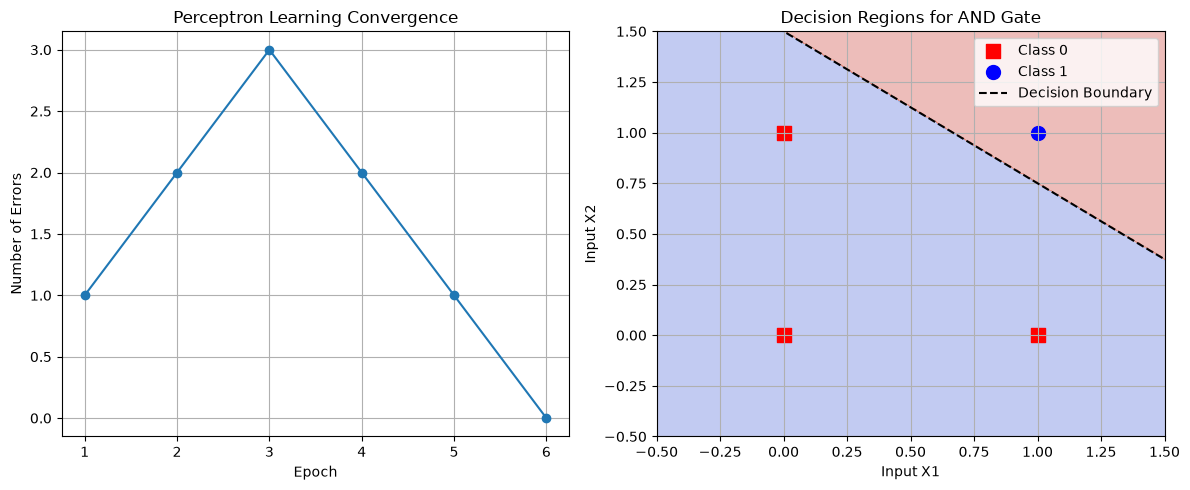

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Dataset (AND Gate)
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

# 2. Initialize parameters
LR = 0.2
max_epochs = 100
weights = np.array([0.3, -0.2])
bias = -0.4
errors = []

# 3. Step function
def step_function(x):
    return 1 if x >= 0 else 0

# 4. Perceptron training
for epoch in range(max_epochs):
    total_error = 0

    for i in range(len(X)):
        net = np.dot(X[i], weights) + bias
        output = step_function(net)

        error = y[i] - output

        weights += LR * error * X[i]
        bias += LR * error

        if error != 0:
            total_error += 1

    errors.append(total_error)

    if total_error == 0:
        print("Training converged in", epoch + 1, "epochs")
        break

# 5. Display results
print("\nOUTPUT ")
print("Final Weights:", weights)
print("Final Bias:", bias)

print("\nAND Gate Predictions:")
for i in range(len(X)):
    net = np.dot(X[i], weights) + bias
    output = step_function(net)
    print(X[i], "=", output)

# 6. Create decision regions
x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = np.dot(grid, weights) + bias
Z = (Z > 0).astype(int)
Z = Z.reshape(xx.shape)

# 7. Plot graphs
plt.figure(figsize=(12, 5))

# Graph 1: Convergence
plt.subplot(1, 2, 1)

epochs = np.arange(1, len(errors) + 1)

plt.plot(epochs, errors, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Number of Errors")
plt.title("Perceptron Learning Convergence")
plt.xticks(epochs)
plt.grid(True)

# Graph 2: Decision Regions
plt.subplot(1, 2, 2)

plt.contourf(
    xx, yy, Z,
    alpha=0.35,
    cmap="coolwarm"
)

plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    color="red", marker="s",
    s=100, label="Class 0"
)

plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    color="blue", marker="o",
    s=100, label="Class 1"
)

# Decision boundary
x1 = np.linspace(x_min, x_max, 100)

if weights[1] != 0:
    x2 = -(weights[0] * x1 + bias) / weights[1]
    plt.plot(x1, x2, 'k--', label="Decision Boundary")

plt.xlabel("Input X1")
plt.ylabel("Input X2")
plt.title("Decision Regions for AND Gate")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()